# Notebook 01: Bond Pricing Fundamentals

**Week 1, Step 5 — experiment, predict, explain.**

Use the pricing functions from Step 4 to investigate how yield, maturity,
and coupon affect price. Before running an experiment, make a prediction;
then explain the result using the timing and size of cash flows.

## Conventions for every experiment

- Hypothetical fixed-rate bonds; prices are **per $100 face value**.
- Coupons are paid semiannually. Valuation is immediately after a coupon
  payment, so accrued interest is zero.
- Yield is an **annual nominal YTM compounded semiannually**, supplied as a
  decimal in Python. It is not an effective annual rate.
- Each bond is priced using one YTM. These plots vary that input; they do
  not represent a market yield curve across maturities.
- Coupon schedules have equal half-year periods. No taxes, fees, defaults,
  or actual-date conventions are modeled.

Run **Kernel → Restart Kernel and Run All Cells** with this project's `.venv`
kernel. The imports show the interpreter and package location so a moved
project is easy to check. No old project path is embedded in this notebook.

In [1]:
%matplotlib inline
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import Markdown, display
import filab
from filab.pricing import fixed_coupon_cashflows, price_coupon_bond, price_zero_coupon

print('Python:', sys.executable)
print('Package:', Path(filab.__file__).resolve())
plt.rcParams.update({
    'figure.figsize': (9, 5),
    'figure.dpi': 120,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.18,
    'font.size': 11,
})
FACE = 100.0
FREQUENCY = 2
YIELDS = np.linspace(0.00, 0.10, 201)

def bond_price(coupon, maturity, ytm):
    return price_coupon_bond(
        face_value=FACE, coupon_rate=coupon, maturity_years=maturity,
        ytm=ytm, frequency=FREQUENCY,
    )

def show_table(headers, rows):
    text = '| ' + ' | '.join(headers) + ' |\n'
    text += '| ' + ' | '.join(['---'] * len(headers)) + ' |\n'
    text += '\n'.join('| ' + ' | '.join(map(str, row)) + ' |' for row in rows)
    display(Markdown(text))

Matplotlib is building the font cache; this may take a moment.


Python: /Users/zhlou/Work/fixed_income_lab/.venv/bin/python
Package: /Users/zhlou/Work/fixed_income_lab/src/filab/__init__.py


## 1. Same coupon, different maturities

**Predict:** If all three bonds have a 4% coupon, where should their prices
meet? Which price will move the most when yield changes from 4% to 5%?

Hold coupon rate and face value fixed. Compare 2-, 10-, and 30-year bonds.
The horizontal axis is the YTM supplied to the pricer, not calendar time.

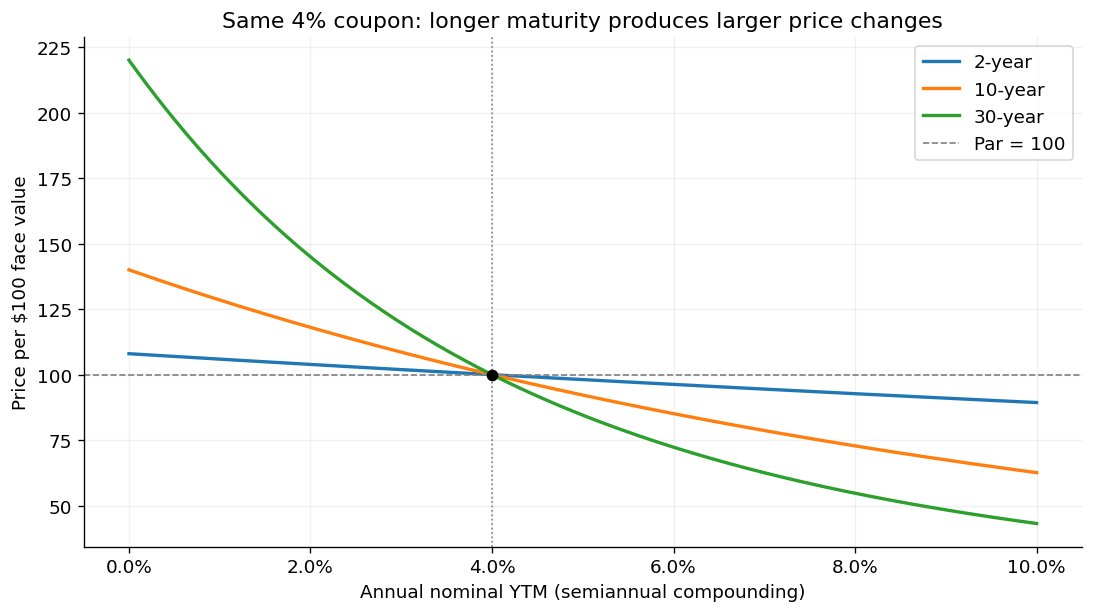

| Maturity | Price at 3% | Price at 4% | Price at 5% | Price change: 4% → 5% |
| --- | --- | --- | --- | --- |
| 2 years | 101.93 | 100.00 | 98.12 | -1.88% |
| 10 years | 108.58 | 100.00 | 92.21 | -7.79% |
| 30 years | 119.69 | 100.00 | 84.55 | -15.45% |

In [2]:
MATURITIES = (2, 10, 30)
COUPON = 0.04
fig, ax = plt.subplots(layout='constrained')
for maturity in MATURITIES:
    prices = [bond_price(COUPON, maturity, y) for y in YIELDS]
    ax.plot(YIELDS, prices, label=f'{maturity}-year', linewidth=2)
ax.axhline(FACE, color='gray', linestyle='--', linewidth=1, label='Par = 100')
ax.axvline(COUPON, color='gray', linestyle=':', linewidth=1)
ax.scatter([COUPON], [FACE], color='black', zorder=4)
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set(xlabel='Annual nominal YTM (semiannual compounding)',
       ylabel='Price per $100 face value',
       title='Same 4% coupon: longer maturity produces larger price changes')
ax.legend()
plt.show()

rows = []
for maturity in MATURITIES:
    p3, p4, p5 = [bond_price(COUPON, maturity, y) for y in (0.03, 0.04, 0.05)]
    rows.append([f'{maturity} years', f'{p3:.2f}', f'{p4:.2f}', f'{p5:.2f}',
                 f'{(p5 / p4 - 1):+.2%}'])
show_table(['Maturity', 'Price at 3%', 'Price at 4%', 'Price at 5%',
            'Price change: 4% → 5%'], rows)

### Read the result

All three price curves pass through par when YTM equals the 4% coupon rate.
Below 4%, the bonds trade at premiums; above 4%, they trade at discounts.
For these otherwise matched bonds, longer maturity puts more weight on
distant payments, producing a larger percentage price response.

A move from 4% to 5% is **one percentage point = 100 basis points**.
It is not a 1% relative increase in the yield.

The table compares immediate prices with the remaining maturity held fixed.
It is not a one-year investment-return calculation: no time passes and no
coupons are received between the two valuations.

## 2. Same maturity and YTM, different coupons

**Predict:** At a 5% YTM and 10-year maturity, which coupon rate produces
par? Why should a higher coupon lead to a higher price?

Hold maturity, YTM, face value, and payment frequency fixed. Change only
the coupon rate. A zero coupon rate leaves just principal at maturity.

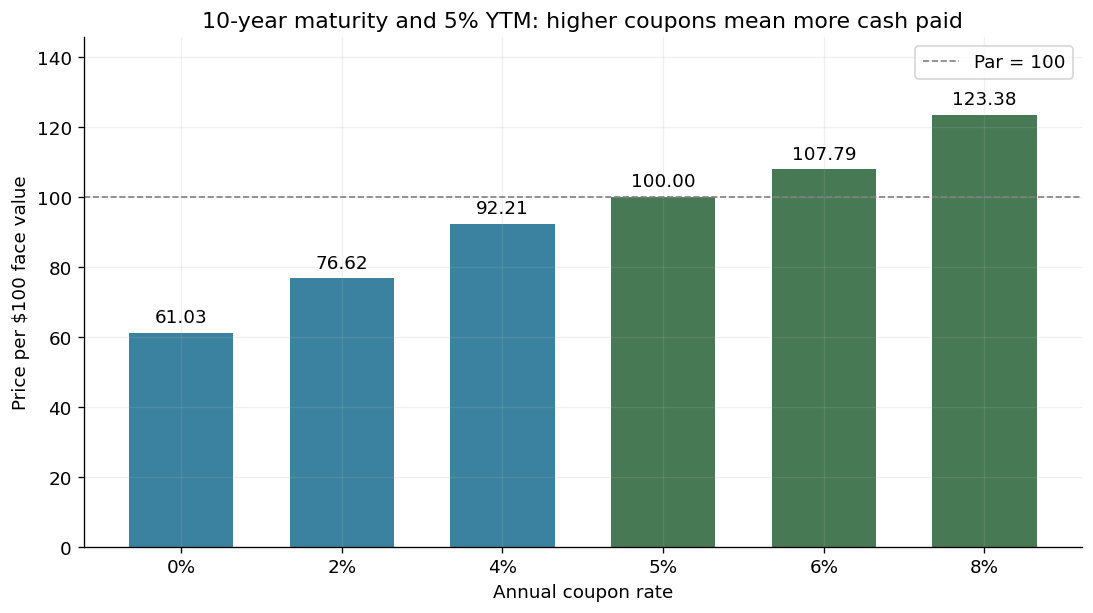

| Coupon | Coupon every six months | Price | Relative to par |
| --- | --- | --- | --- |
| 0% | $0.00 | 61.03 | Discount |
| 2% | $1.00 | 76.62 | Discount |
| 4% | $2.00 | 92.21 | Discount |
| 5% | $2.50 | 100.00 | At par |
| 6% | $3.00 | 107.79 | Premium |
| 8% | $4.00 | 123.38 | Premium |

In [3]:
FIXED_MATURITY = 10
FIXED_YTM = 0.05
COUPONS = (0.00, 0.02, 0.04, 0.05, 0.06, 0.08)
coupon_prices = [bond_price(c, FIXED_MATURITY, FIXED_YTM) for c in COUPONS]

fig, ax = plt.subplots(layout='constrained')
colors = ['#3b82a0' if c < FIXED_YTM else '#477a54' for c in COUPONS]
bars = ax.bar([f'{c:.0%}' for c in COUPONS], coupon_prices, color=colors, width=0.65)
ax.bar_label(bars, labels=[f'{p:.2f}' for p in coupon_prices], padding=4)
ax.axhline(FACE, color='gray', linestyle='--', linewidth=1, label='Par = 100')
ax.set(xlabel='Annual coupon rate', ylabel='Price per $100 face value',
       title='10-year maturity and 5% YTM: higher coupons mean more cash paid',
       ylim=(0, max(coupon_prices) * 1.18))
ax.legend()
plt.show()

show_table(['Coupon', 'Coupon every six months', 'Price', 'Relative to par'], [
    [f'{c:.0%}', f'${FACE * c / FREQUENCY:.2f}', f'{p:.2f}',
     'At par' if np.isclose(p, FACE) else ('Premium' if p > FACE else 'Discount')]
    for c, p in zip(COUPONS, coupon_prices)
])

### Read the result

Increasing the coupon increases each periodic payment while leaving the
principal unchanged. Discounting a larger set of payments at the same
rate gives a larger price. The 5% coupon bond is at par under these
conventions.

The zero-coupon bond's lower price does not make it a bargain: it promises
less cash. Price comparisons require looking at the associated payments.

## 3. Coupon timing and percentage sensitivity

**Predict:** Compare a 10-year zero-coupon bond with a 10-year 4% coupon
bond. Which has the larger percentage price change when YTM rises from
5% to 6%?

Their starting prices differ, so normalize each price to its own value
at 5% YTM. This compares proportional sensitivity rather than price levels.

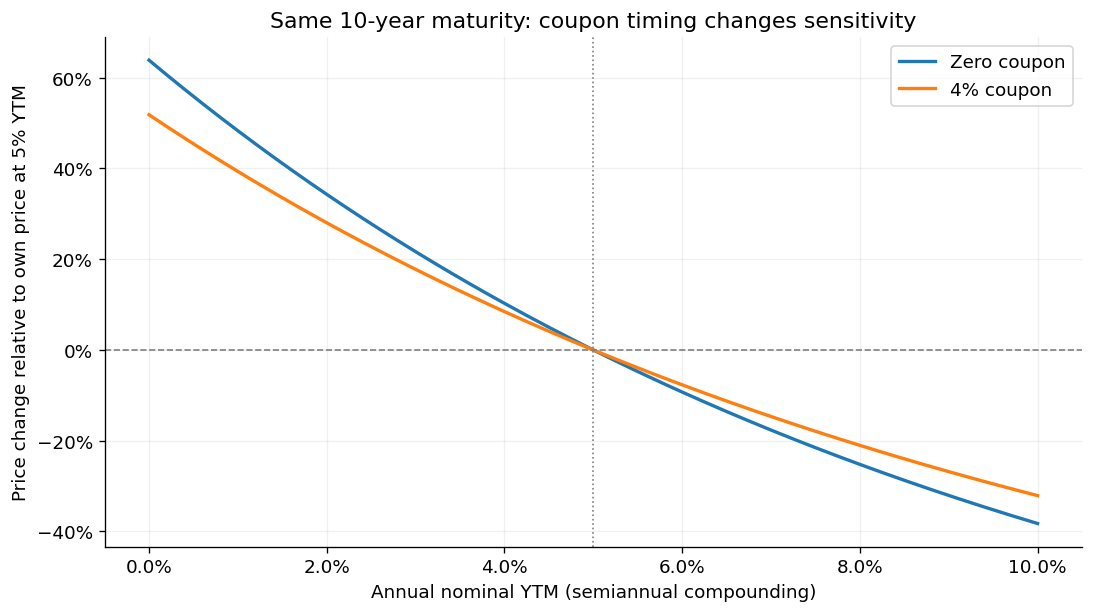

| Bond | Price at 5% | Price at 6% | Percentage price change |
| --- | --- | --- | --- |
| Zero coupon | 61.03 | 55.37 | -9.27% |
| 4% coupon | 92.21 | 85.12 | -7.68% |

In [4]:
fig, ax = plt.subplots(layout='constrained')
response_rows = []
for coupon, label in [(0.00, 'Zero coupon'), (0.04, '4% coupon')]:
    baseline = bond_price(coupon, 10, 0.05)
    changes = [bond_price(coupon, 10, y) / baseline - 1 for y in YIELDS]
    ax.plot(YIELDS, changes, label=label, linewidth=2)
    shocked = bond_price(coupon, 10, 0.06)
    response_rows.append([label, f'{baseline:.2f}', f'{shocked:.2f}',
                          f'{shocked / baseline - 1:+.2%}'])
ax.axhline(0, color='gray', linestyle='--', linewidth=1)
ax.axvline(0.05, color='gray', linestyle=':', linewidth=1)
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set(xlabel='Annual nominal YTM (semiannual compounding)',
       ylabel='Price change relative to own price at 5% YTM',
       title='Same 10-year maturity: coupon timing changes sensitivity')
ax.legend()
plt.show()
show_table(['Bond', 'Price at 5%', 'Price at 6%', 'Percentage price change'], response_rows)

### Read the result

The zero-coupon bond receives everything at the end. The coupon bond
receives some money earlier, making its percentage price change smaller
in this comparison. Maturity alone does not determine sensitivity.
Duration will put a number on this timing difference in Weeks 3–4.

## 4. Interactive explorer

Move one control at a time. The controls use percentages (enter **4** for 4%),
and convert them into decimals before calling the pricing function.
The displayed yield shock is an immediate repricing, not a realized return.

The interactive output needs a live kernel and `ipywidgets` from the project's
development dependencies. The three figures above remain visible without it.

In [5]:
def explore_bond(maturity_years=10, coupon_pct=4.0, ytm_pct=5.0):
    coupon, ytm = coupon_pct / 100, ytm_pct / 100
    current = bond_price(coupon, maturity_years, ytm)
    shocked = bond_price(coupon, maturity_years, ytm + 0.01)
    fig, ax = plt.subplots(layout='constrained')
    curve = [bond_price(coupon, maturity_years, y) for y in YIELDS]
    ax.plot(YIELDS, curve, color='#3b82a0', linewidth=2)
    ax.axhline(FACE, color='gray', linestyle='--', linewidth=1)
    ax.scatter([ytm], [current], color='#bd632f', s=65, zorder=4,
               label=f'Selected price: {current:.2f}')
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.set(xlabel='Annual nominal YTM (semiannual compounding)',
           ylabel='Price per $100 face value',
           title=f'{maturity_years}-year bond, {coupon_pct:g}% coupon')
    ax.legend()
    plt.show()
    print(f'Price per $100 face: {current:.4f}')
    print(f'Coupon every six months: ${FACE * coupon / FREQUENCY:.2f}')
    print(f'Price at YTM + 100 bp: {shocked:.4f} '
          f'({shocked / current - 1:+.2%} immediate price change)')

try:
    import ipywidgets as widgets
except ImportError:
    print("For sliders, install development dependencies: python -m pip install -e '.[dev]'")
    explore_bond()
else:
    explorer = widgets.interactive(
        explore_bond,
        maturity_years=widgets.Dropdown(options=[2, 10, 30], value=10, description='Years'),
        coupon_pct=widgets.FloatSlider(value=4, min=0, max=8, step=0.5,
                                      description='Coupon %', continuous_update=False),
        ytm_pct=widgets.FloatSlider(value=5, min=0, max=10, step=0.25,
                                   description='YTM %', continuous_update=False),
    )
    display(explorer)

interactive(children=(Dropdown(description='Years', index=1, options=(2, 10, 30), value=10), FloatSlider(value…

## 5. Numerical checks on these experiments

These assertions check the financial relationships used above, independently
of the visual appearance of the charts. The full package tests are in `tests/`.

In [6]:
for maturity in MATURITIES:
    assert np.isclose(bond_price(0.04, maturity, 0.04), FACE)
    prices = np.array([bond_price(0.04, maturity, y) for y in YIELDS])
    assert np.all(np.diff(prices) < 0)

assert np.all(np.diff(coupon_prices) > 0)
assert np.isclose(bond_price(0.04, 2, 0.05), 98.11901289599514)
assert np.isclose(
    bond_price(0, 10, 0.05),
    price_zero_coupon(face_value=FACE, ytm=0.05, maturity_years=10),
)
zero_change = bond_price(0, 10, 0.06) / bond_price(0, 10, 0.05) - 1
coupon_change = bond_price(0.04, 10, 0.06) / bond_price(0.04, 10, 0.05) - 1
assert zero_change < coupon_change < 0
print('All experiment checks passed.')

All experiment checks passed.


## 6. Write your explanation

Replace the prompts below with your own answers. The earlier sections contain
the numerical evidence, so cite a price or percentage change when you can.

1. Why do the 4% coupon curves all meet at a price of 100 when YTM is 4%?
2. Which of the three maturities loses the most when YTM rises from 4% to 5%?
   Explain using payment timing.
3. At a fixed 5% YTM, why does increasing coupon rate raise price?
4. Why do two bonds with the same maturity and YTM have different percentage
   sensitivity when their coupons differ?
5. Why is the horizontal axis in Experiment 1 not a Treasury yield curve?
6. Why is the change from the 4% price to the 5% price not a one-year total return?

**Next step:** Finish the validation and reflection checklist for Week 1.
Week 2 adds YTM solving, accrued interest, and settlement conventions.